In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("heart.csv")   # sesuaikan dengan nama file yang kamu unduh

print(df.shape)
print(df.head())
print(df.info())
print("Missing values:\n", df.isnull().sum())
print(df.describe())

(918, 12)
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0

HeartDisease
1    508
0    410
Name: count, dtype: int64
HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


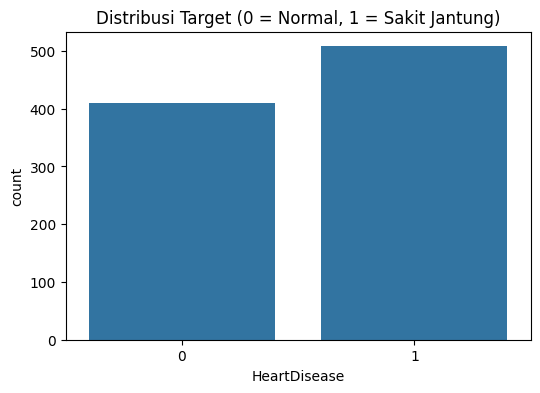

In [2]:
print(df["HeartDisease"].value_counts())
print(df["HeartDisease"].value_counts(normalize=True).round(3))

plt.figure(figsize=(6, 4))
sns.countplot(x="HeartDisease", data=df)
plt.title("Distribusi Target (0 = Normal, 1 = Sakit Jantung)")
plt.show()

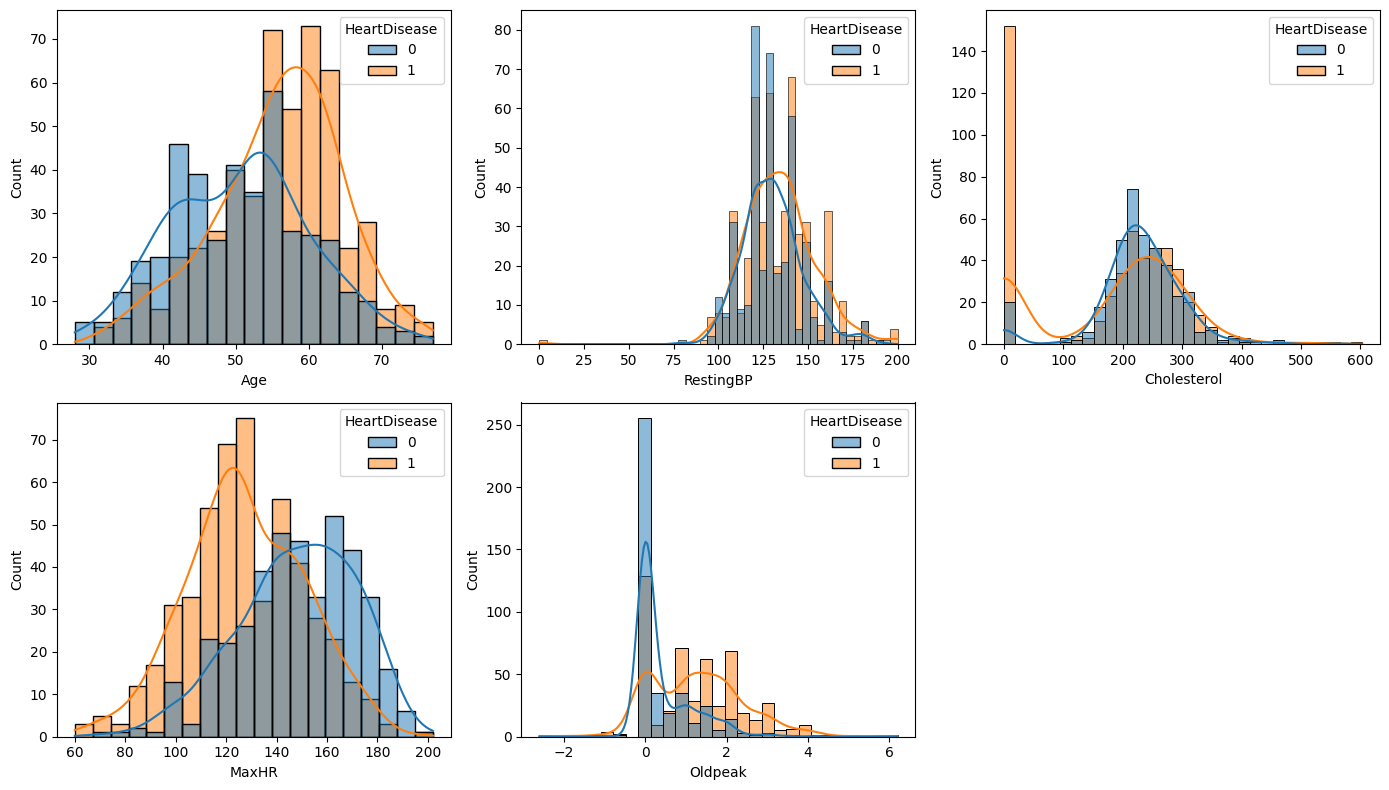

In [3]:
fitur_num = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, kol in zip(axes.flat, fitur_num):
    sns.histplot(data=df, x=kol, hue="HeartDisease", kde=True, ax=ax)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

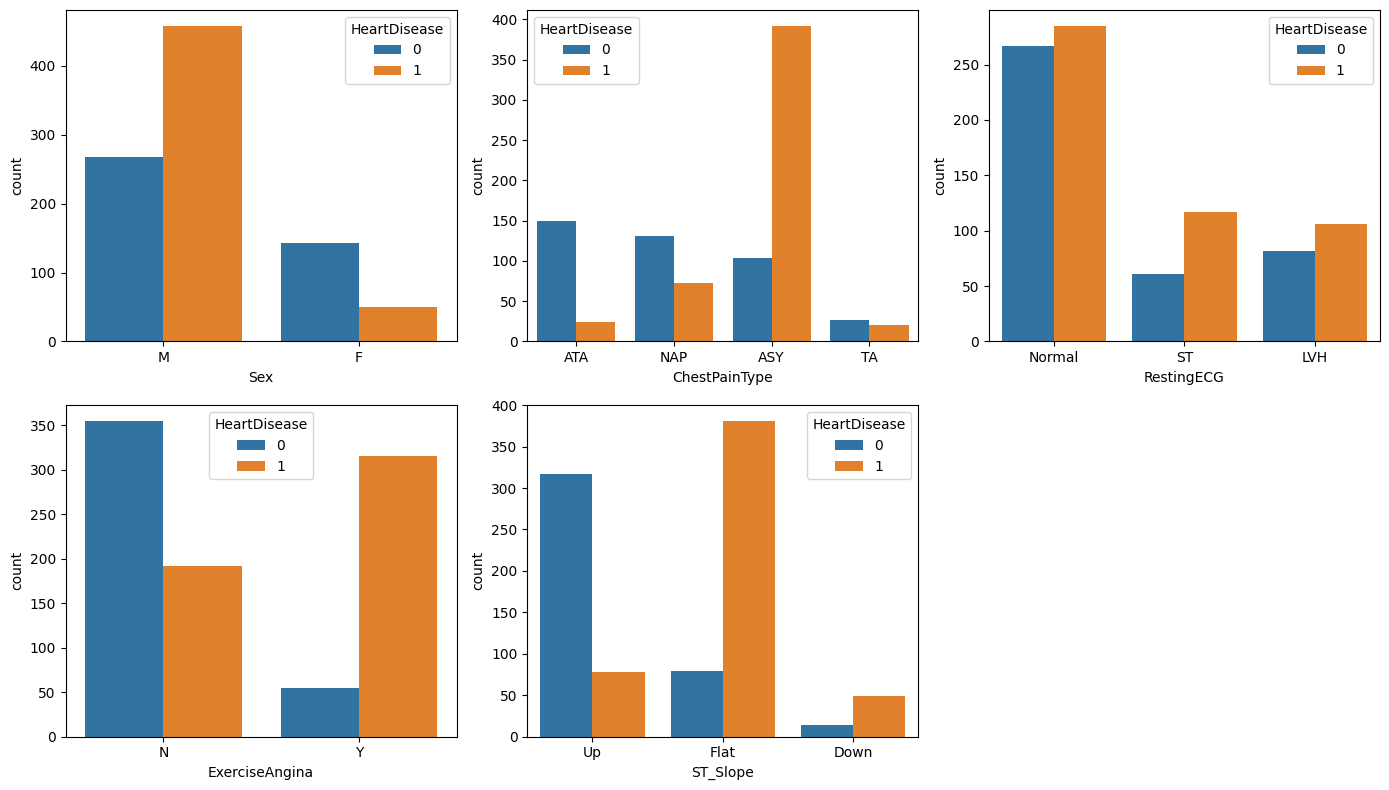

In [4]:
fitur_kat = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, kol in zip(axes.flat, fitur_kat):
    sns.countplot(data=df, x=kol, hue="HeartDisease", ax=ax)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

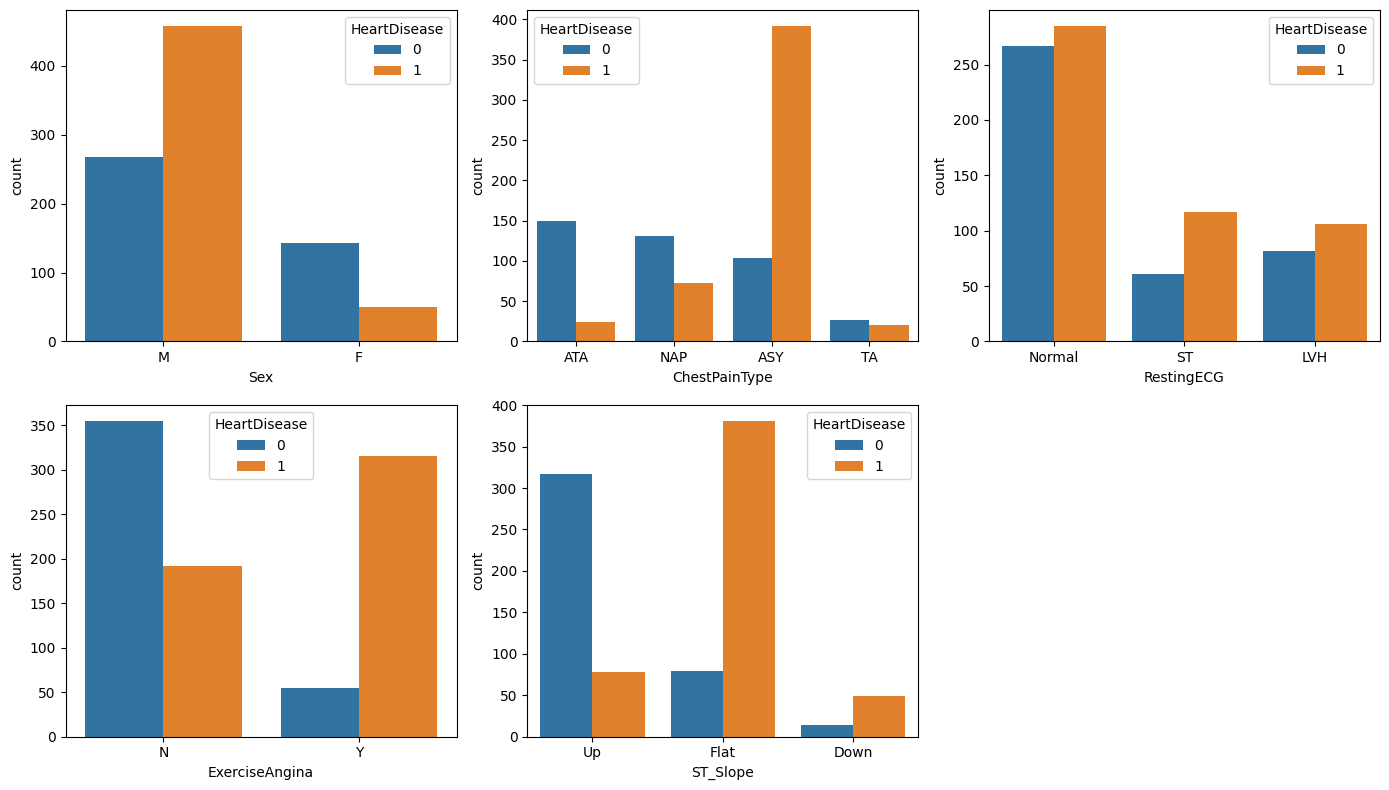

In [5]:
fitur_kat = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, kol in zip(axes.flat, fitur_kat):
    sns.countplot(data=df, x=kol, hue="HeartDisease", ax=ax)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Ubah kolom kategorikal jadi angka (one-hot)
df_model = pd.get_dummies(df, columns=fitur_kat, drop_first=True, dtype=int)

X = df_model.drop(columns="HeartDisease").astype(float)
y = df_model["HeartDisease"]

# 2. Bagi data (stratify menjaga proporsi kelas tetap sama)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_test = X_train.copy(), X_test.copy()

# 3. Nilai 0 yang tidak masuk akal -> isi median data LATIH (bukan seluruh data)
for kol in ["RestingBP", "Cholesterol"]:
    median = X_train.loc[X_train[kol] > 0, kol].median()
    X_train.loc[X_train[kol] == 0, kol] = median
    X_test.loc[X_test[kol] == 0, kol] = median

# 4. Scaling hanya pada fitur numerik
scaler = StandardScaler()
X_train[fitur_num] = scaler.fit_transform(X_train[fitur_num])
X_test[fitur_num] = scaler.transform(X_test[fitur_num])

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Kolom fitur:", list(X.columns))

Data latih: (734, 15) | Data uji: (184, 15)
Kolom fitur: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up']


In [7]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

               precision    recall  f1-score   support

       Normal       0.89      0.85      0.87        82
Sakit Jantung       0.89      0.91      0.90       102

     accuracy                           0.89       184
    macro avg       0.89      0.88      0.88       184
 weighted avg       0.89      0.89      0.89       184



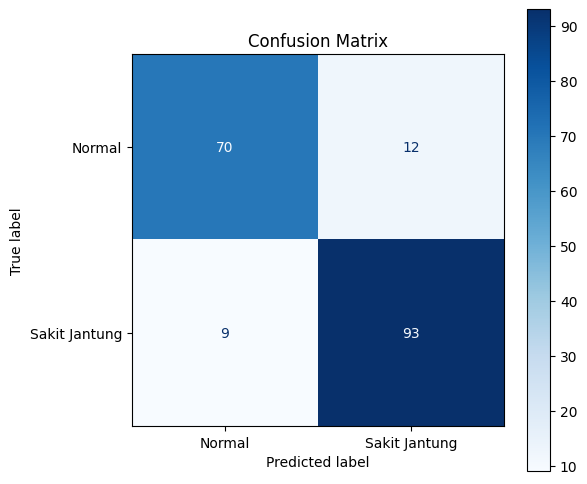

In [8]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pred = model.predict(X_test)

print(classification_report(y_test, pred, target_names=["Normal", "Sakit Jantung"]))

cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Sakit Jantung"]).plot(cmap="Blues", ax=ax)
plt.title("Confusion Matrix")
plt.show()

AUC: 0.9329


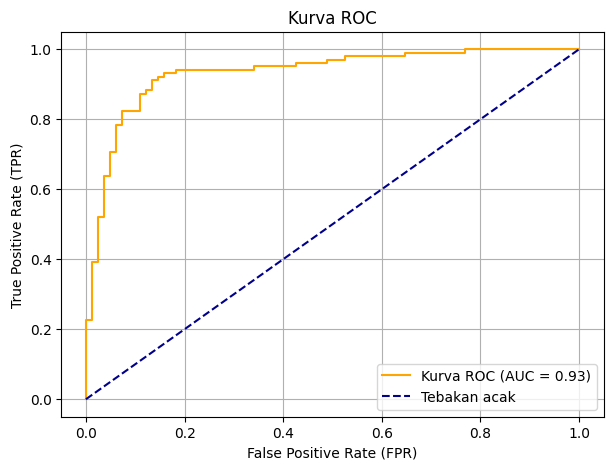

In [9]:
from sklearn.metrics import roc_curve, roc_auc_score

proba = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
print(f"AUC: {auc:.4f}")

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="orange", label=f"Kurva ROC (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], "--", color="darkblue", label="Tebakan acak")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Kurva ROC")
plt.legend()
plt.grid(True)
plt.show()

ChestPainType_NAP   -1.583656
ChestPainType_ATA   -1.528086
ST_Slope_Up         -1.393562
ChestPainType_TA    -1.120788
MaxHR               -0.303811
RestingECG_Normal   -0.181089
RestingECG_ST       -0.124499
RestingBP           -0.031073
Cholesterol          0.050112
Age                  0.067373
Oldpeak              0.255157
ExerciseAngina_Y     0.841557
ST_Slope_Flat        0.914003
FastingBS            1.165743
Sex_M                1.291433
dtype: float64


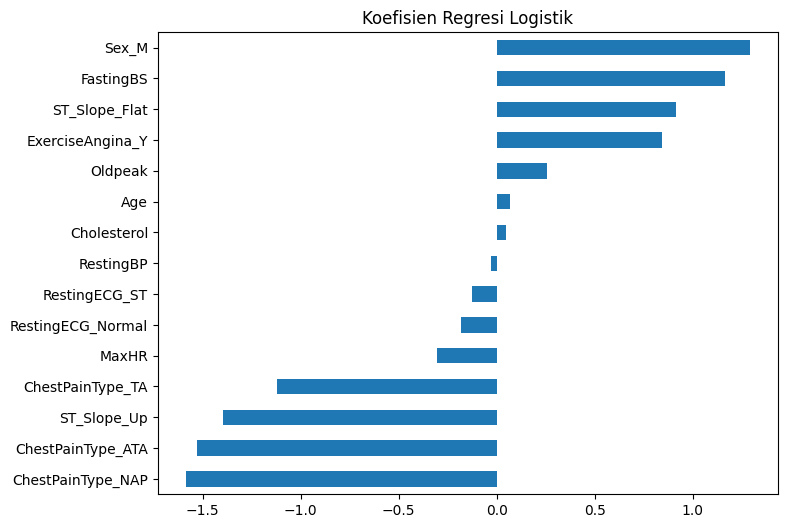

In [10]:
koef = pd.Series(model.coef_[0], index=X.columns).sort_values()
print(koef)
koef.plot(kind="barh", figsize=(8, 6), title="Koefisien Regresi Logistik")
plt.show()

In [11]:
import joblib

joblib.dump(model, "model_jantung.pkl")
joblib.dump(scaler, "scaler_jantung.pkl")
joblib.dump(list(X.columns), "kolom_fitur.pkl")

# Tes: muat ulang
m = joblib.load("model_jantung.pkl")
print("Model termuat:", type(m).__name__)
print("Jumlah fitur:", len(joblib.load("kolom_fitur.pkl")))

Model termuat: LogisticRegression
Jumlah fitur: 15


In [12]:
!pip install flask -q

import threading
from app import app
from google.colab import output

threading.Thread(target=lambda: app.run(port=5000, use_reloader=False)).start()
output.serve_kernel_port_as_window(5000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [13]:
import sklearn, pandas, numpy, joblib, sys
isi = f"""flask
gunicorn
scikit-learn=={sklearn.__version__}
pandas=={pandas.__version__}
numpy=={numpy.__version__}
joblib=={joblib.__version__}
"""
open("/content/requirements.txt", "w").write(isi)
print(isi)
print("Python Colab:", sys.version.split()[0])

flask
gunicorn
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
joblib==1.6.0

Python Colab: 3.13.16


In [14]:
%cd /content
!rm -rf templates/.ipynb_checkpoints
!mv Requirements.txt requirements.txt.lama 2>/dev/null
!mv Readme README.md 2>/dev/null
!rm -rf paket && mkdir paket
!cp -r app.py requirements.txt README.md heart.csv model_jantung.pkl scaler_jantung.pkl kolom_fitur.pkl templates paket/
!ls -R paket
!cd paket && zip -r ../ta03-jantung.zip .

from google.colab import files
files.download("ta03-jantung.zip")

/content
paket:
app.py	   kolom_fitur.pkl    README.md		scaler_jantung.pkl
heart.csv  model_jantung.pkl  requirements.txt	templates

paket/templates:
index.html
  adding: kolom_fitur.pkl (deflated 29%)
  adding: templates/ (stored 0%)
  adding: templates/index.html (deflated 73%)
  adding: README.md (deflated 35%)
  adding: heart.csv (deflated 77%)
  adding: requirements.txt (deflated 8%)
  adding: model_jantung.pkl (deflated 37%)
  adding: scaler_jantung.pkl (deflated 35%)
  adding: app.py (deflated 62%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>